# JADES · Extract a 1D spectrum from a 2D FITS image

Each row of the 2D image is a spatial position. Each column is a wavelength bin. Summing the rows with `np.nansum(image, axis=0)` gives one flux value per wavelength.

Run from the repository root to use the local archive. In Colab, place the archive in **My Drive** and approve the Drive mount when prompted. Then run all cells.

[JADES data access](https://jades-survey.github.io/scientists/data.html) · [CLEAR/PRISM archive](https://drive.google.com/file/d/1rpZSoMC-6rzwGjZtV2B2HhgUqj-m5QZR/view)

## 1. Read the archive and sum the spatial rows

In [1]:
from pathlib import Path
from io import BytesIO
import tarfile

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

path = Path("hlsp_jades_jwst_nirspec_clear-prism.tar.xz")
if not path.exists():
    from google.colab import drive
    drive.mount("/content/drive")
    path = Path("/content/drive/MyDrive") / path

images, extracted, published = {}, {}, {}
with tarfile.open(path, "r|xz") as archive:
    for member in archive:
        if not member.isfile() or not member.name.endswith(("_s2d.fits", "_x1d.fits")):
            continue
        name, product = Path(member.name).name.rsplit("_", 1)
        with archive.extractfile(member) as entry, fits.open(BytesIO(entry.read())) as hdu:
            if product == "s2d.fits":
                image = hdu["FLUX"].data
                images[name] = image.astype(np.float32)
                flux = np.nansum(image, axis=0)
                flux[np.isnan(image).all(axis=0)] = np.nan
                extracted[name] = (hdu["WAVELENGTH"].data.copy(), flux)
            else:
                table = hdu["EXTRACT1D"].data
                published[name] = (table["WAVELENGTH"].copy(), table["FLUX"].copy())

assert extracted.keys() == published.keys()
print(f"Matched pairs: {len(extracted):,}")

Matched pairs: 3,752


## 2. Compare the extracted and published spectra

Calculate RMSE over wavelength bins with finite flux in both spectra. The published extraction uses a narrower aperture, so its flux can differ from the sum of every spatial row. The loop compares all pairs.

In [2]:
rmse = {}
shared_bins = 0
for name, (wave, flux) in extracted.items():
    ref_wave, ref_flux = published[name]
    np.testing.assert_allclose(wave, ref_wave, rtol=0, atol=1e-10)
    valid = np.isfinite(wave) & np.isfinite(flux) & np.isfinite(ref_flux)
    shared_bins += valid.sum()
    rmse[name] = np.sqrt(np.mean((flux[valid] - ref_flux[valid]) ** 2))

print(f"Compared {len(rmse):,} pairs over {shared_bins:,} wavelength bins")
print(f"Median RMSE: {np.median(list(rmse.values())):.3e} erg s⁻¹ cm⁻² Å⁻¹")



Compared 3,752 pairs over 2,500,361 wavelength bins
Median RMSE: 2.706e-20 erg s⁻¹ cm⁻² Å⁻¹


## 3. Separate plots for the first 15 targets

Targets are sorted by FITS filename. Each target has three separate figures: the original 2D spectrum, the extracted 1D spectrum, and the comparison with the published 1D spectrum.

In [3]:
scale = 1e-20
flux_label = "Flux density (10⁻²⁰ erg s⁻¹ cm⁻² Å⁻¹)"

targets = sorted(extracted)[:15]

def show_target(target):
    title = target.removeprefix("hlsp_jades_jwst_nirspec_")
    wave, flux = extracted[target]
    ref_wave, ref_flux = published[target]
    image = images[target] / scale

    plt.figure(figsize=(8, 3), layout="constrained")
    limit = np.nanpercentile(np.abs(image), 98)
    heatmap = plt.pcolormesh(wave, np.arange(image.shape[0]), image,
                             shading="nearest", cmap="RdBu_r",
                             vmin=-limit, vmax=limit)
    plt.colorbar(heatmap, label=flux_label)
    plt.title(f"{title}\n1. Original 2D spectrum")
    plt.xlabel("Observed wavelength (µm)")
    plt.ylabel("Spatial row")
    plt.show()

    plt.figure(figsize=(8, 3), layout="constrained")
    plt.plot(wave, flux / scale)
    plt.title(f"{title}\n2. Extracted 1D spectrum")
    plt.xlabel("Observed wavelength (µm)")
    plt.ylabel(flux_label)
    plt.show()

    plt.figure(figsize=(8, 3), layout="constrained")
    plt.plot(wave, flux / scale, label="Spatial sum")
    plt.plot(ref_wave, ref_flux / scale, label="Published 1D", color="black")
    plt.title(f"{title}\n3. Comparison with published 1D")
    plt.xlabel("Observed wavelength (µm)")
    plt.ylabel(flux_label)
    plt.legend()
    plt.show()

### 1. goods-n-mediumhst-00000604_clear-prism_v1.0

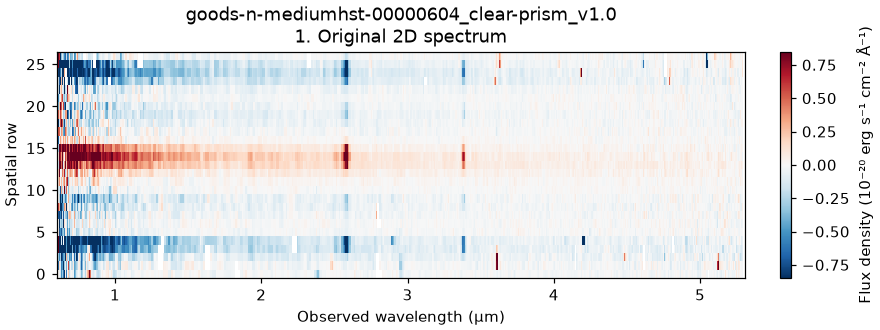

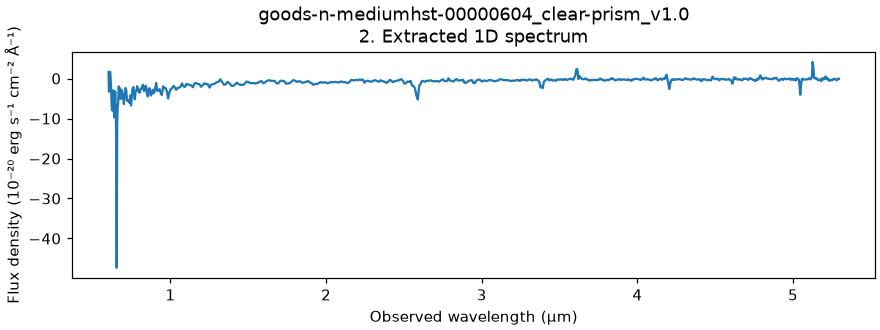

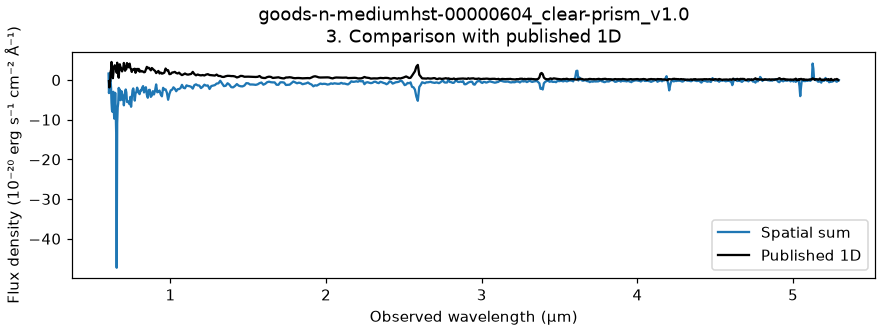

In [4]:
show_target(targets[0])

### 2. goods-n-mediumhst-00000606_clear-prism_v1.0

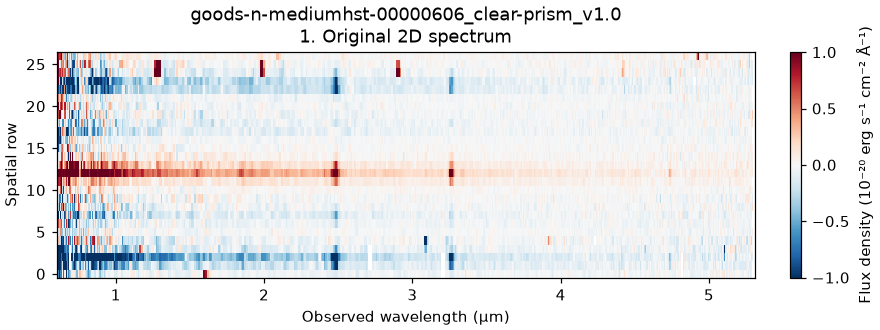

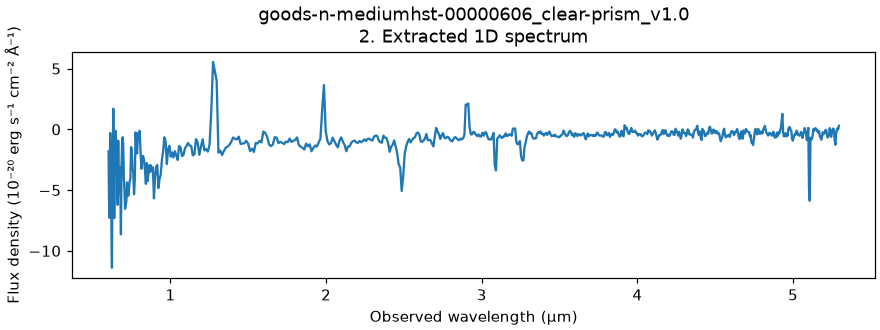

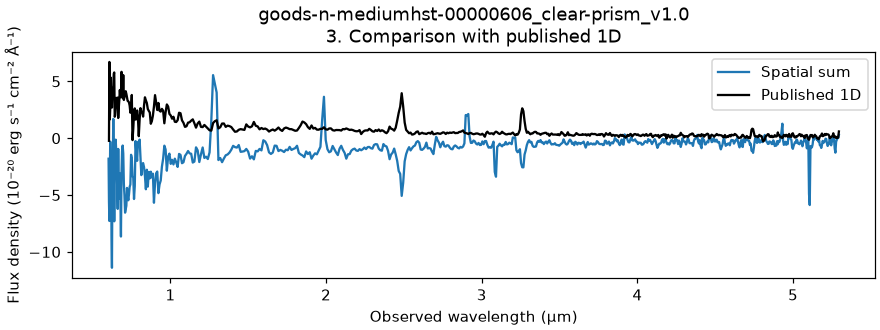

In [5]:
show_target(targets[1])

### 3. goods-n-mediumhst-00000607_clear-prism_v1.0

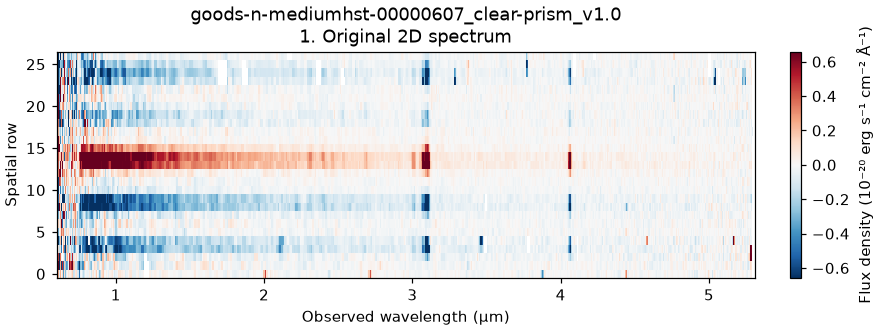

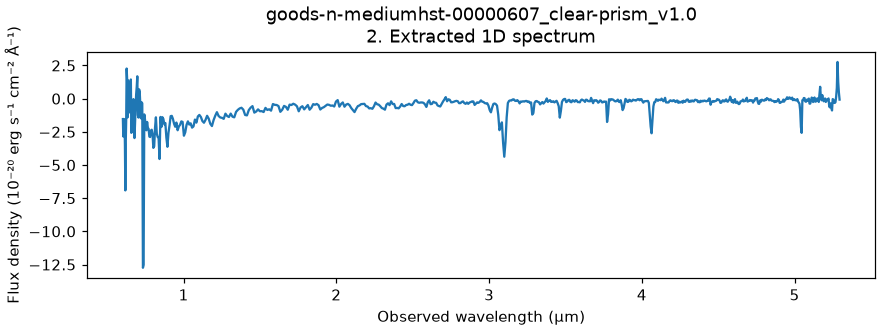

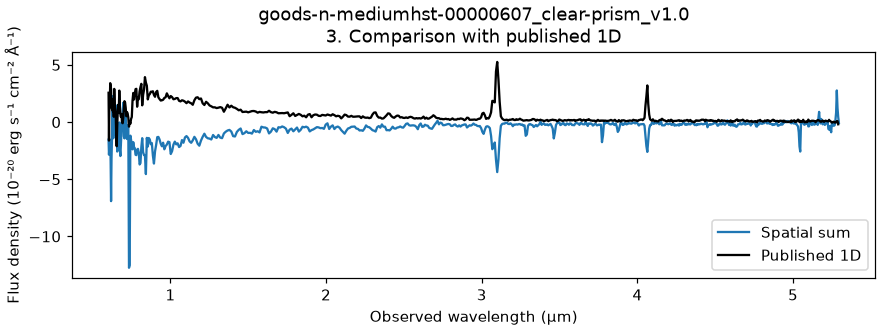

In [6]:
show_target(targets[2])

### 4. goods-n-mediumhst-00000634_clear-prism_v1.0

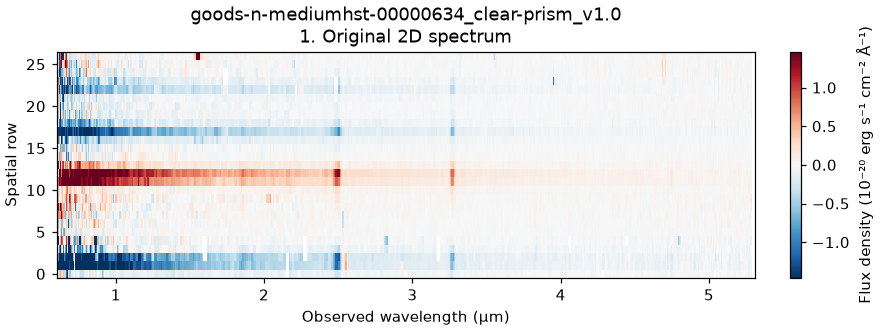

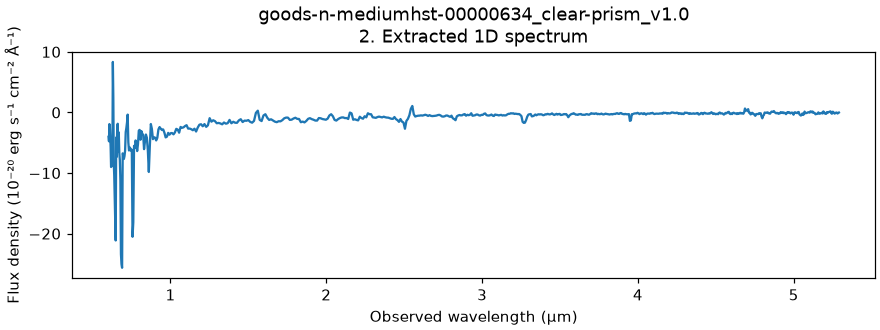

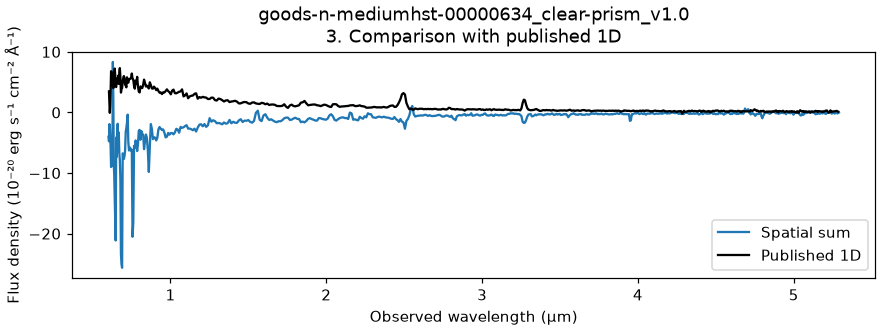

In [7]:
show_target(targets[3])

### 5. goods-n-mediumhst-00000643_clear-prism_v1.0

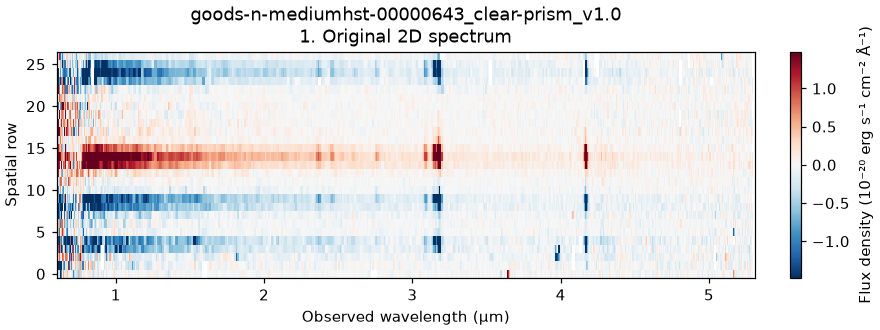

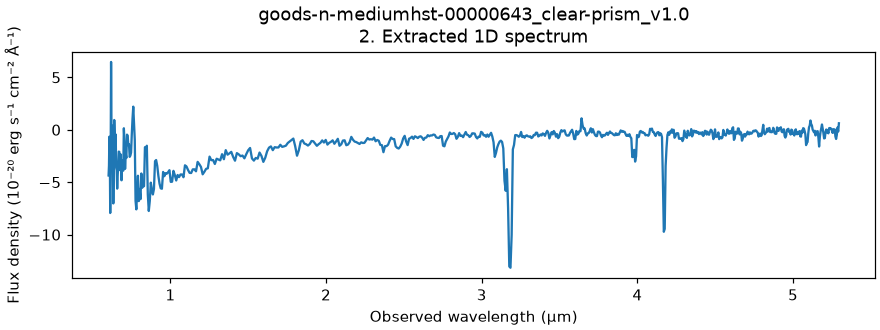

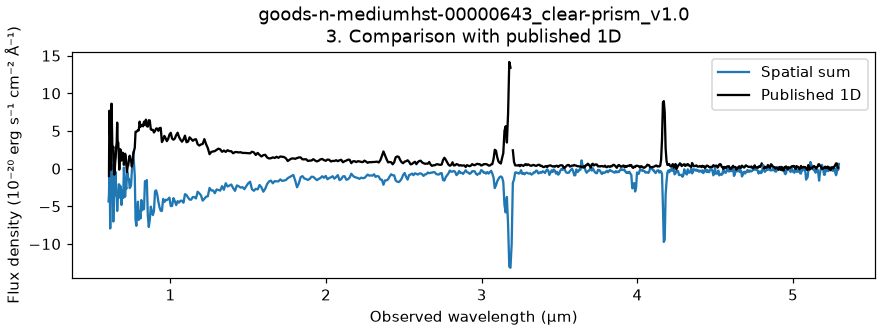

In [8]:
show_target(targets[4])

### 6. goods-n-mediumhst-00000666_clear-prism_v1.0

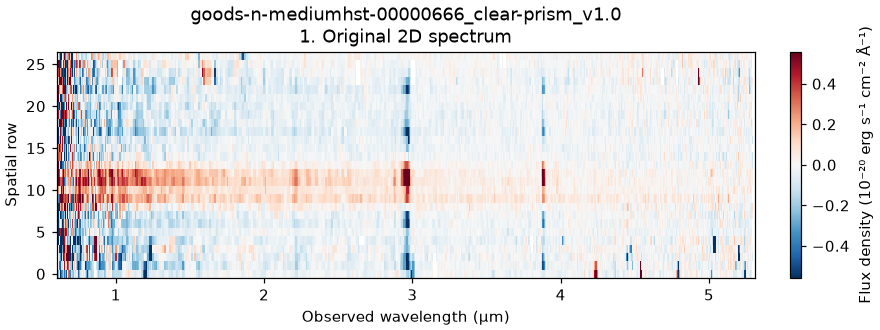

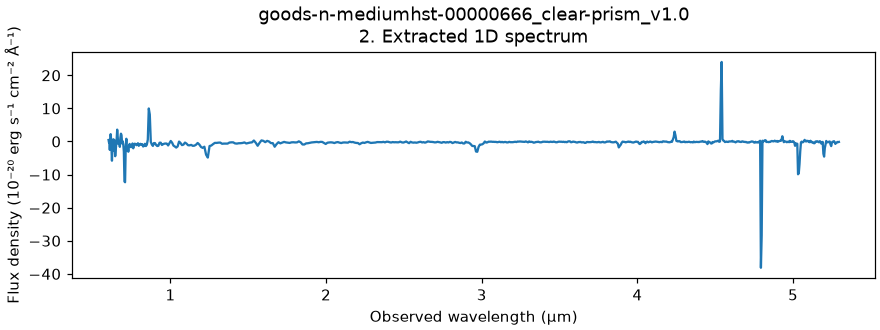

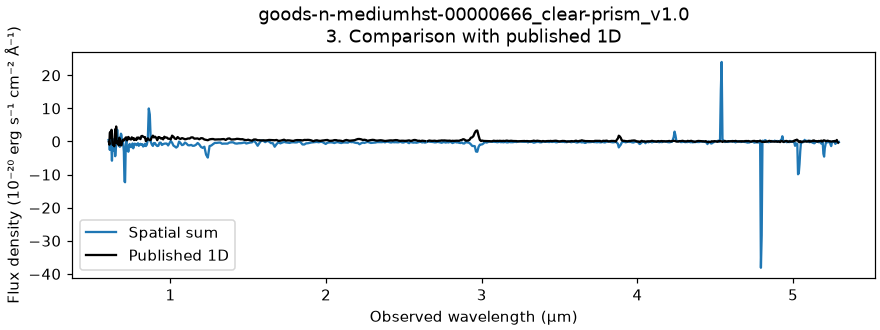

In [9]:
show_target(targets[5])

### 7. goods-n-mediumhst-00000721_clear-prism_v1.0

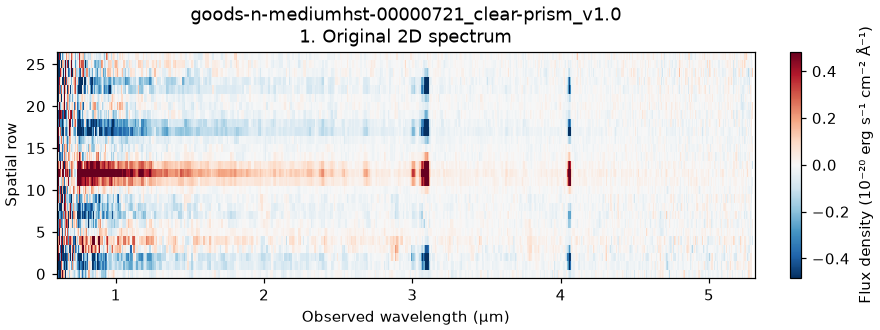

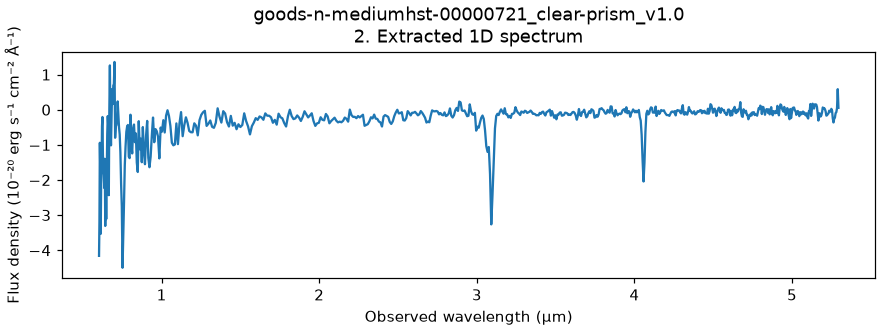

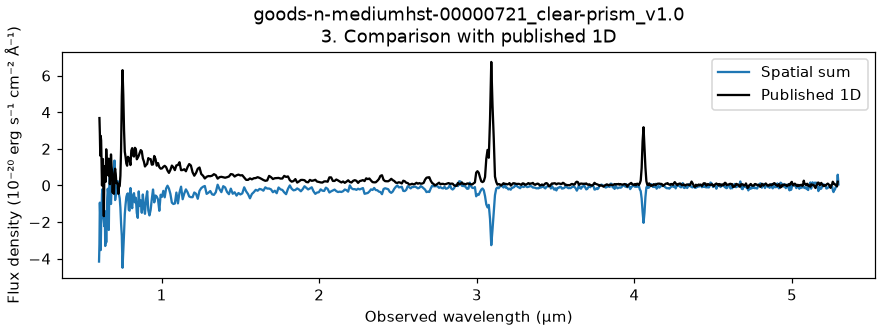

In [10]:
show_target(targets[6])

### 8. goods-n-mediumhst-00000755_clear-prism_v1.0

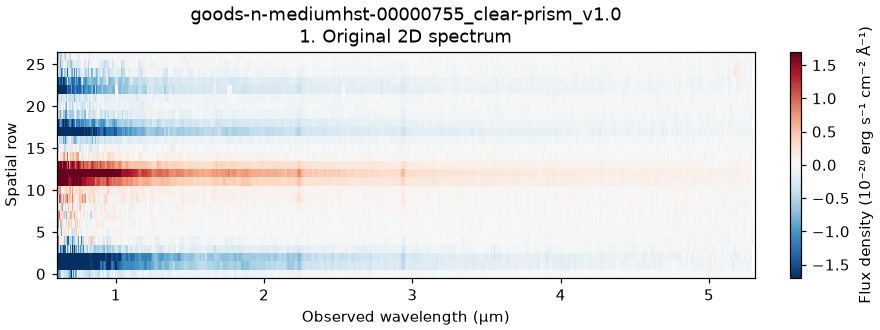

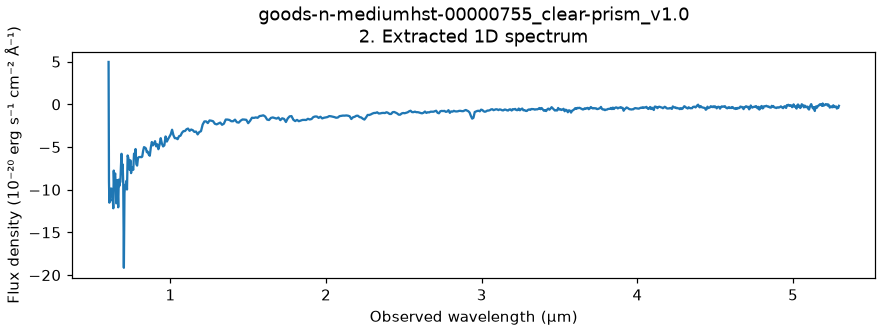

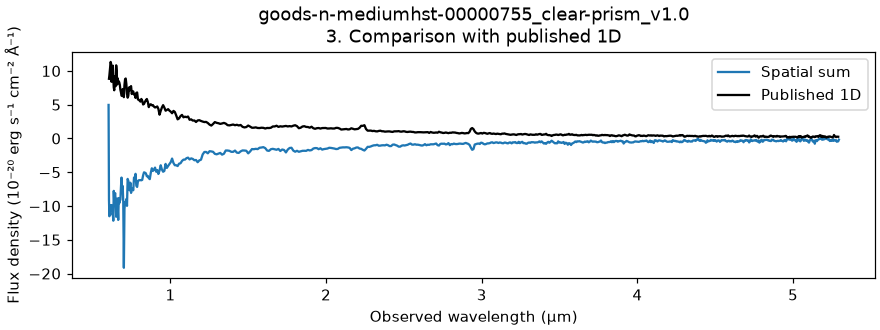

In [11]:
show_target(targets[7])

### 9. goods-n-mediumhst-00000758_clear-prism_v1.0

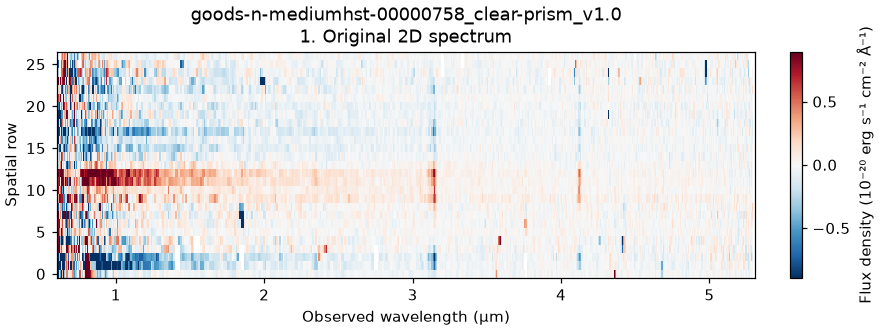

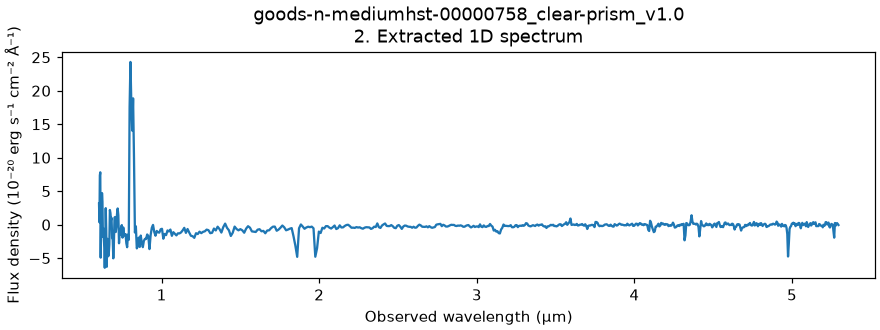

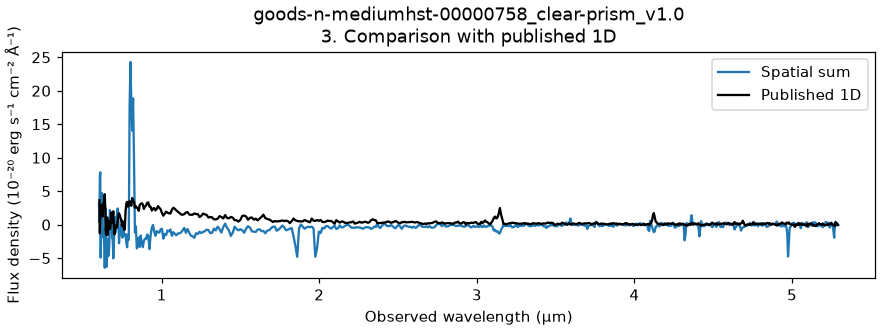

In [12]:
show_target(targets[8])

### 10. goods-n-mediumhst-00000761_clear-prism_v1.0

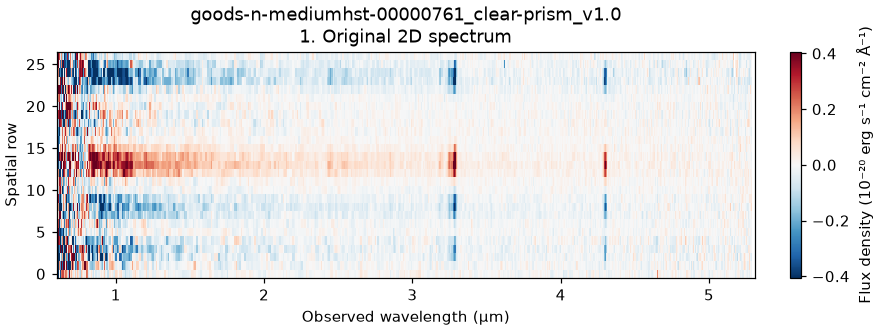

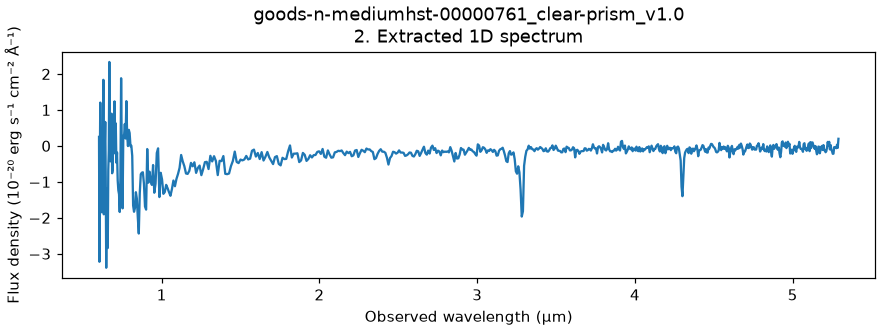

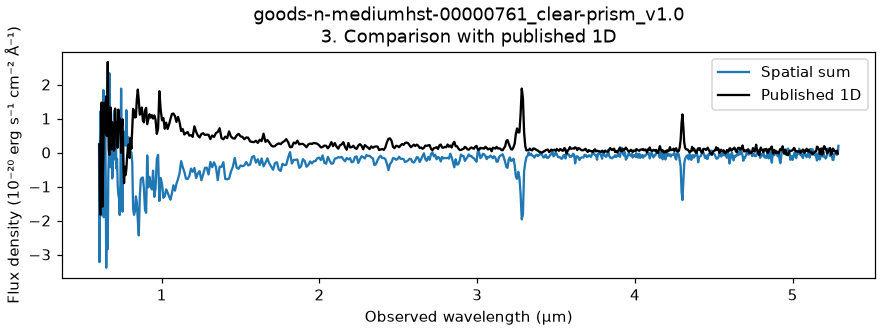

In [13]:
show_target(targets[9])

### 11. goods-n-mediumhst-00000772_clear-prism_v1.0

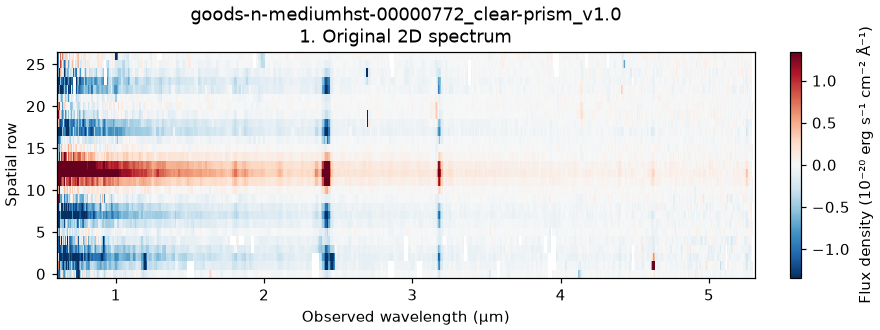

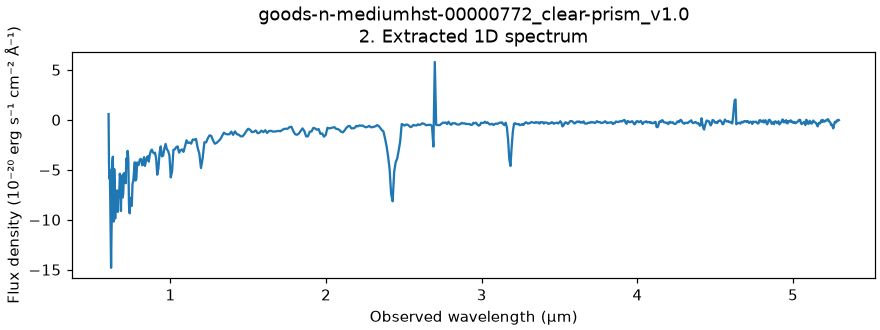

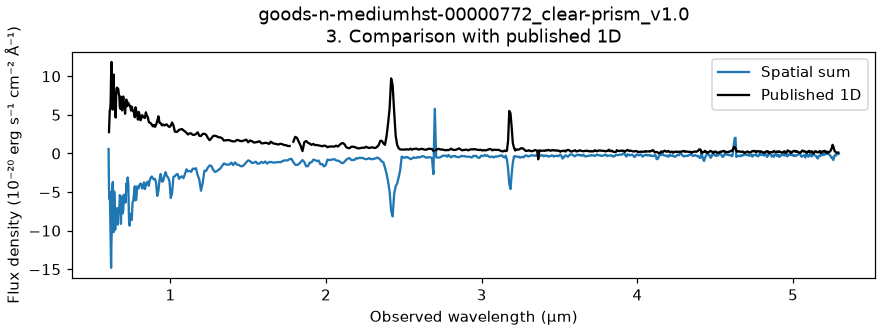

In [14]:
show_target(targets[10])

### 12. goods-n-mediumhst-00000777_clear-prism_v1.0

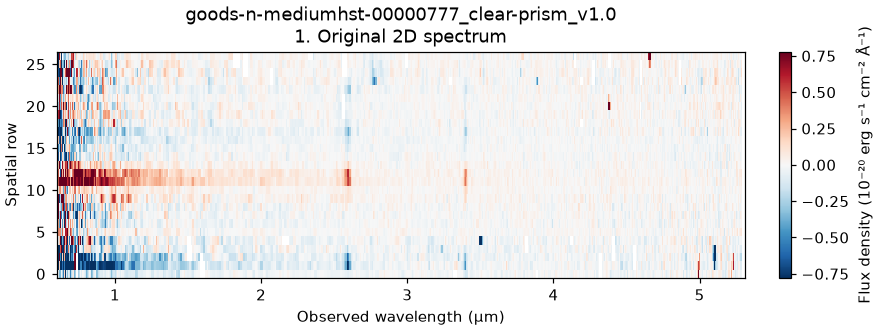

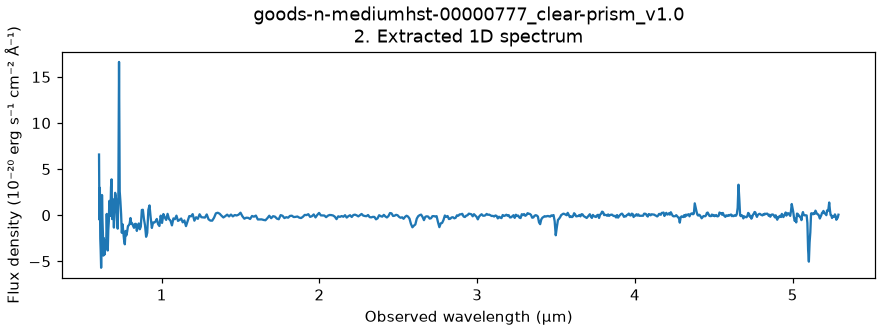

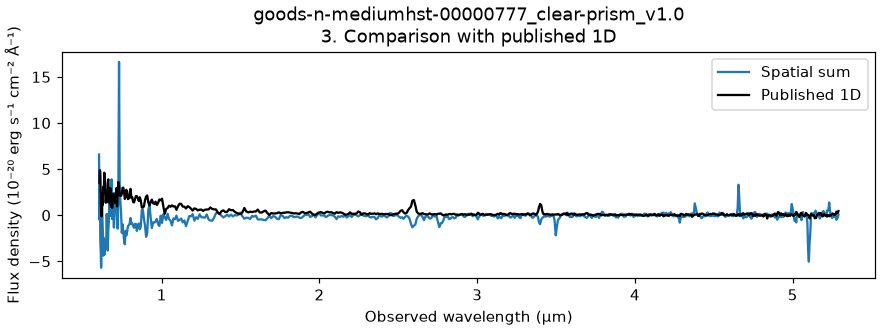

In [15]:
show_target(targets[11])

### 13. goods-n-mediumhst-00000795_clear-prism_v1.0

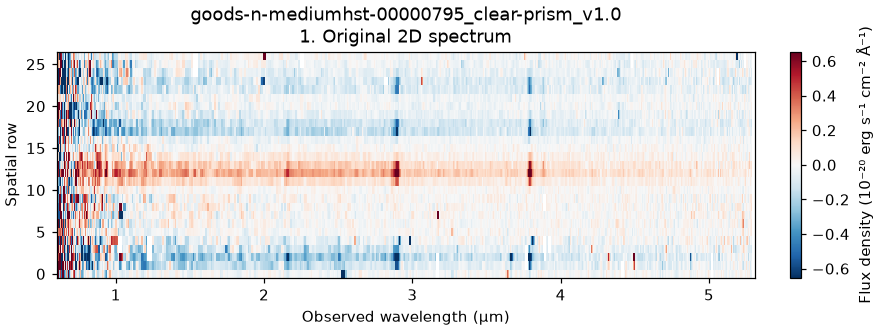

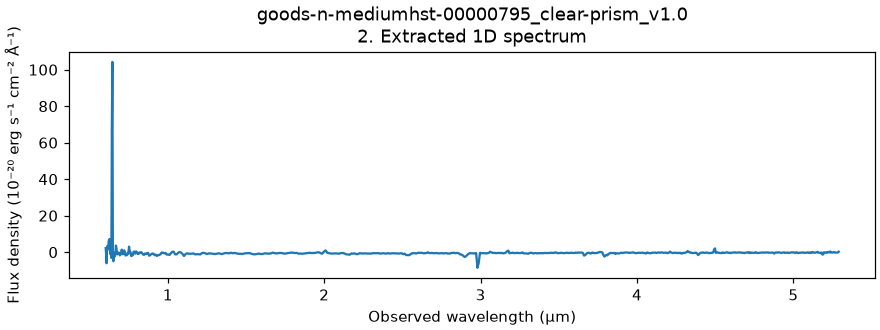

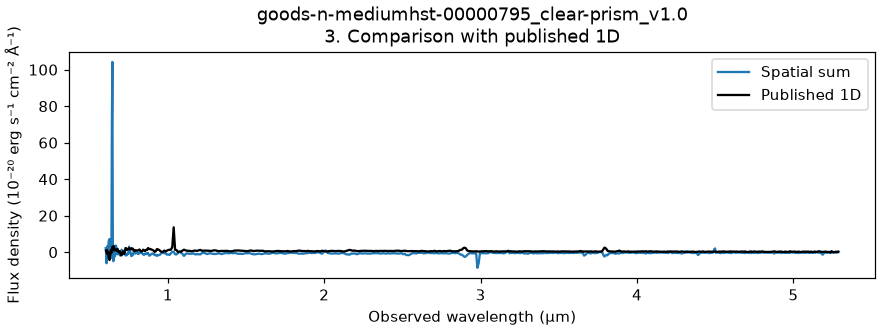

In [16]:
show_target(targets[12])

### 14. goods-n-mediumhst-00000804_clear-prism_v1.0

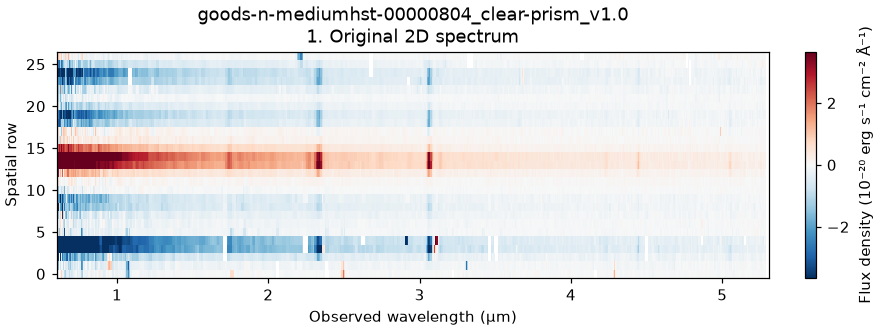

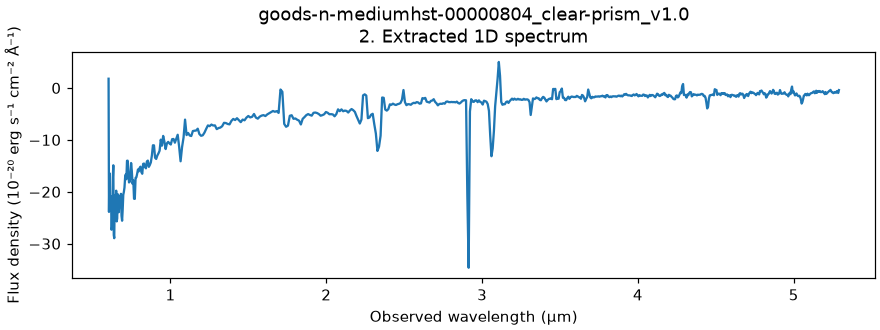

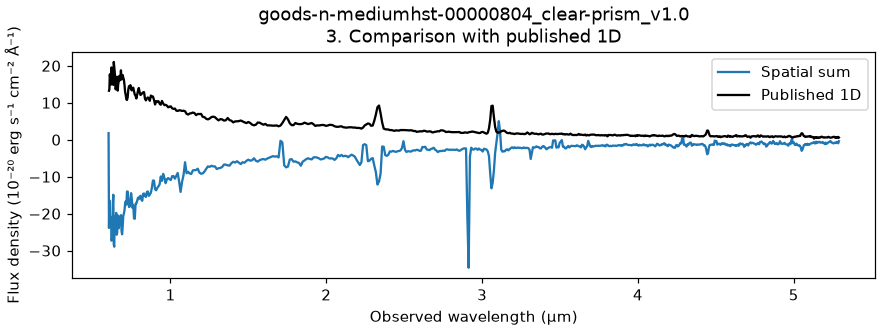

In [17]:
show_target(targets[13])

### 15. goods-n-mediumhst-00000834_clear-prism_v1.0

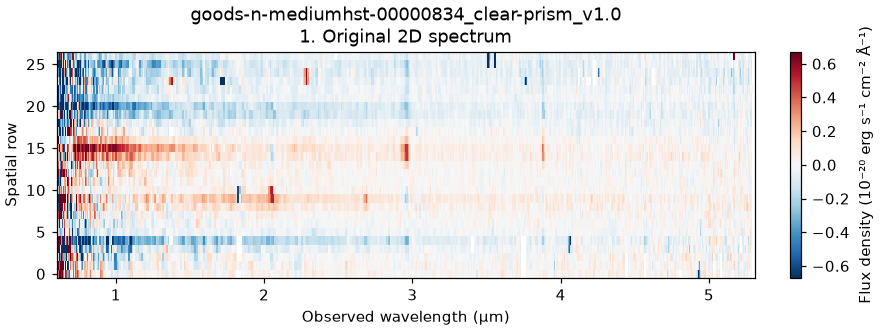

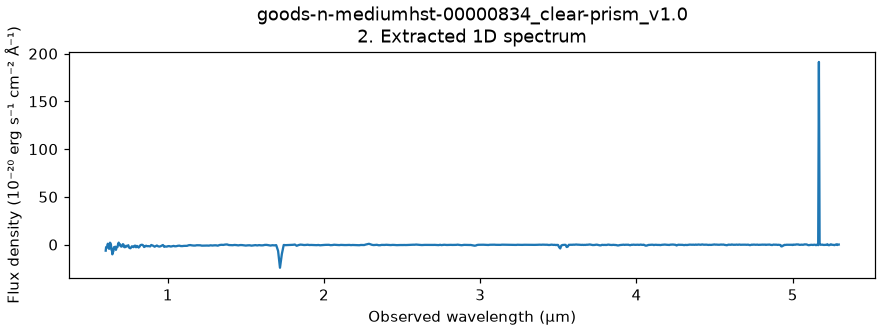

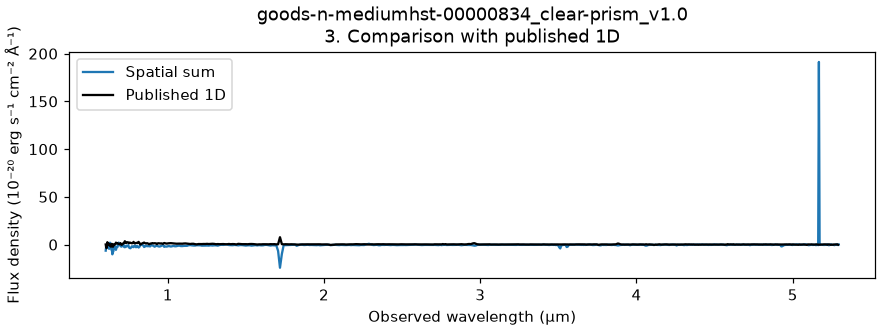

In [18]:
show_target(targets[14])